# 0. Data Retrieval and Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pytrends.request import TrendReq
from numpy.linalg import inv

In [2]:
# Fetch data from Google Trends
pytrends = TrendReq(hl='en-US', tz=360)
kw_list = ['yahoo']
pytrends.build_payload(kw_list, cat=0, timeframe='2004-01-01 2025-01-01', geo='', gprop='')
data = pytrends.interest_over_time()
data = data.resample('M').mean().drop(columns='isPartial')

C:\Users\19927\AppData\Local\Temp\ipykernel_53244\2463036745.py:6: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  data = data.resample('M').mean().drop(columns='isPartial')


In [3]:
# Preprocess data
data.reset_index(inplace=True)
data['t'] = np.arange(len(data))
y = data['yahoo'].values
t = data['t'].values

# (a) Visual Evaluation for Polynomial Degree Selection

In [4]:
# Fit polynomials of degrees 1 to 5
degrees = range(1, 6)
coefficients = {}
for deg in degrees:
    coeffs = np.polyfit(t, y, deg)
    coefficients[deg] = coeffs

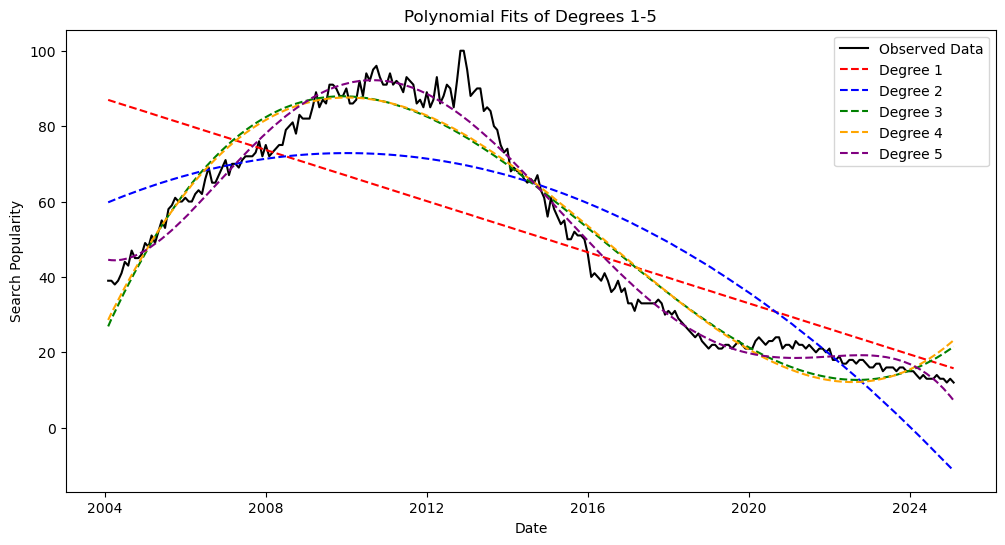

In [5]:
# Plot fits
plt.figure(figsize=(12, 6))
plt.plot(data['date'], y, label='Observed Data', color='black')
colors = ['red', 'blue', 'green', 'orange', 'purple']
for deg, color in zip(degrees, colors):
    fit = np.polyval(coefficients[deg], t)
    plt.plot(data['date'], fit, label=f'Degree {deg}', color=color, linestyle='--')
plt.legend()
plt.title('Polynomial Fits of Degrees 1-5')
plt.xlabel('Date')
plt.ylabel('Search Popularity')
plt.show()

# (b) Bayesian Linear Regression and Posterior Sampling

In [6]:
# Design matrix for k=3
k = 3
X = np.column_stack([t**i for i in range(k+1)])

In [7]:
# Bayesian linear regression with non-informative prior
n = len(y)
XpX = X.T @ X
Xpy = X.T @ y
posterior_cov = inv(XpX)
posterior_mean = posterior_cov @ Xpy
residuals = y - X @ posterior_mean
sigma_sq = (residuals @ residuals) / (n - k - 1)

In [8]:
# Sample from posterior
num_samples = 300
beta_samples = np.random.multivariate_normal(posterior_mean, sigma_sq * posterior_cov, size=num_samples)

C:\Users\19927\AppData\Local\Temp\ipykernel_53244\549831815.py:3: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  beta_samples = np.random.multivariate_normal(posterior_mean, sigma_sq * posterior_cov, size=num_samples)


In [9]:
# Generate predictions for samples
t_range = np.linspace(t.min(), t.max(), 300)
# Convert t_range to dates: since original data is monthly, we create a date range with the same number of points
date_range = pd.date_range(start=data['date'].min(), end=data['date'].max(), periods=300)
X_range = np.column_stack([t_range**i for i in range(k+1)])
y_samples = X_range @ beta_samples.T  # shape: (300, num_samples)

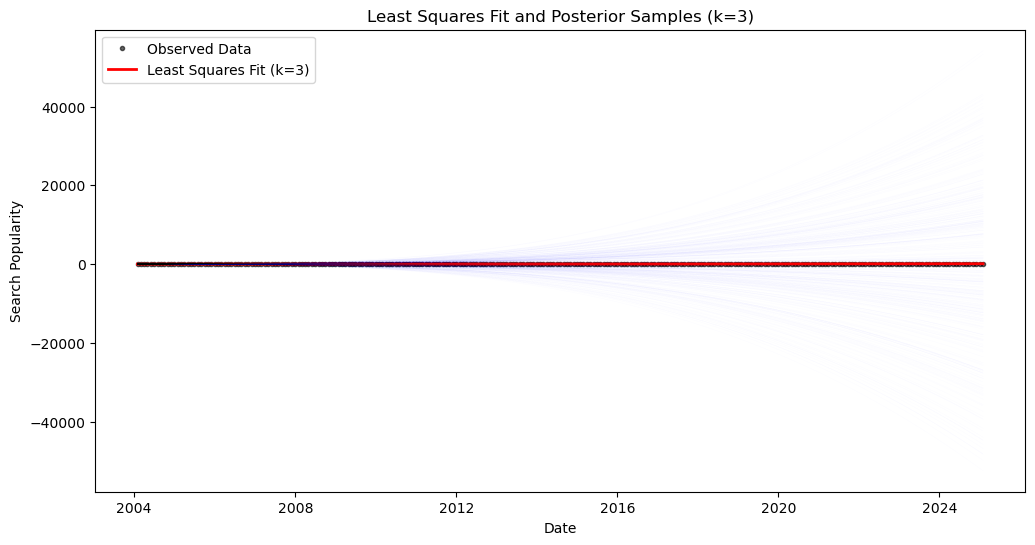

In [10]:
# Plot observed data, least squares fit, and posterior samples
plt.figure(figsize=(12, 6))
plt.plot(data['date'], y, 'k.', label='Observed Data', alpha=0.6)
plt.plot(data['date'], X @ posterior_mean, 'r-', label='Least Squares Fit (k=3)', linewidth=2)
# Plot each posterior sample as a thin blue line with low alpha
for i in range(num_samples):
    plt.plot(date_range, y_samples[:, i], 'b-', alpha=0.01, linewidth=0.5)
plt.title('Least Squares Fit and Posterior Samples (k=3)')
plt.xlabel('Date')
plt.ylabel('Search Popularity')
plt.legend()
plt.show()